In [ ]:
from google.colab import files
uploaded = files.upload()

Saving netflix_final.csv to netflix_final.csv


In [ ]:
import pandas as pd

df = pd.read_csv('netflix_final.csv')
print(df.shape)
df.head()

(8807, 13)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,field13
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Not Specified,United States,25-Sep-21,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",NaN
1,s2,TV Show,Blood & Water,Not Specified,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,24-Sep-21,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",NaN
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,24-Sep-21,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,NaN
3,s4,TV Show,Jailbirds New Orleans,Not Specified,Not Specified,Unknown,24-Sep-21,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",NaN
4,s5,TV Show,Kota Factory,Not Specified,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,24-Sep-21,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,NaN


In [ ]:
# Drop the junk leftover column
df = df.drop(columns=['field13'])

# Quick sanity check - confirm no more country/cast mixup
print(df['country'].value_counts().head(10))

country
United States     2818
India              972
Unknown            831
United Kingdom     419
Japan              245
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Name: count, dtype: int64


/tmp/ipykernel_10288/3400261822.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='type', palette=['#E50914', '#221f1f'])


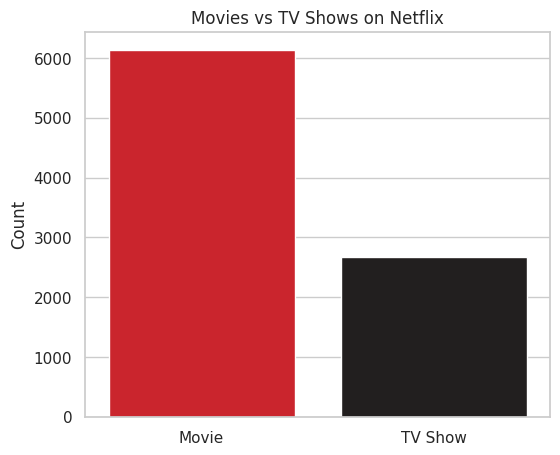

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(6,5))
sns.countplot(data=df, x='type', palette=['#E50914', '#221f1f'])
plt.title('Movies vs TV Shows on Netflix')
plt.xlabel('')
plt.ylabel('Count')
plt.show()

/tmp/ipykernel_10288/1428890193.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='Reds_r')


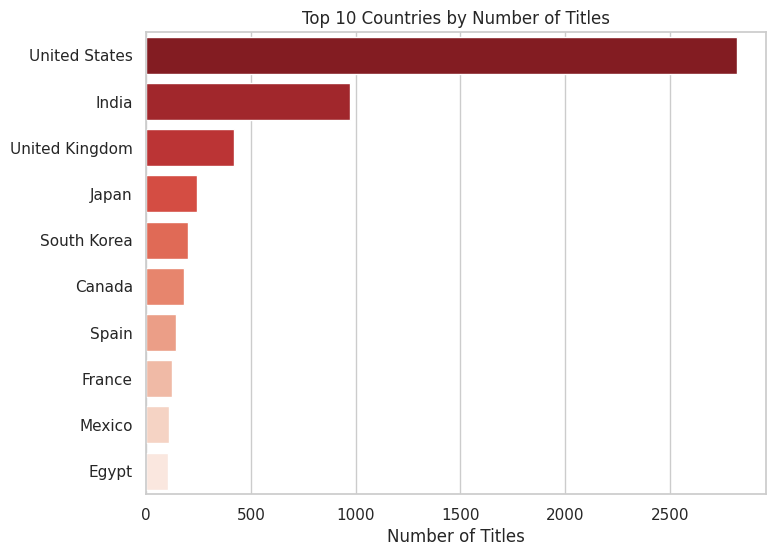

In [ ]:
plt.figure(figsize=(8,6))
top_countries = df[df['country'] != 'Unknown']['country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, palette='Reds_r')
plt.title('Top 10 Countries by Number of Titles')
plt.xlabel('Number of Titles')
plt.ylabel('')
plt.show()

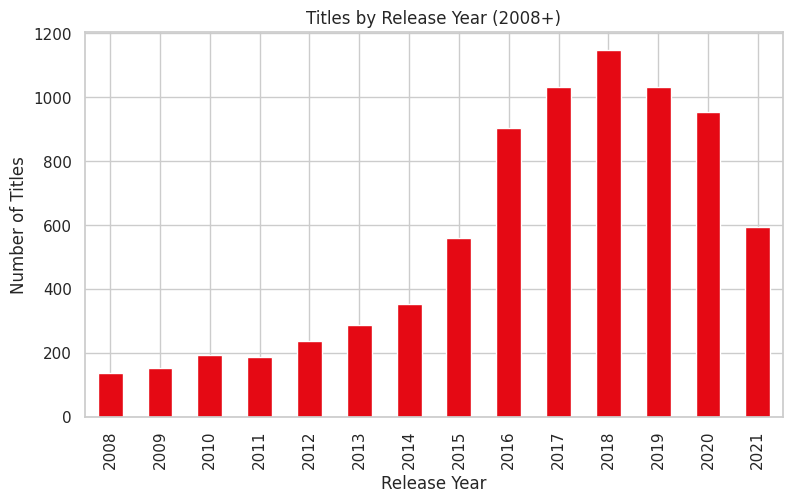

In [ ]:
plt.figure(figsize=(9,5))
year_counts = df['release_year'].value_counts().sort_index()
year_counts[year_counts.index >= 2008].plot(kind='bar', color='#E50914')
plt.title('Titles by Release Year (2008+)')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.show()

/tmp/ipykernel_10288/3000782154.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genres.values, y=top_genres.index, palette='Reds_r')


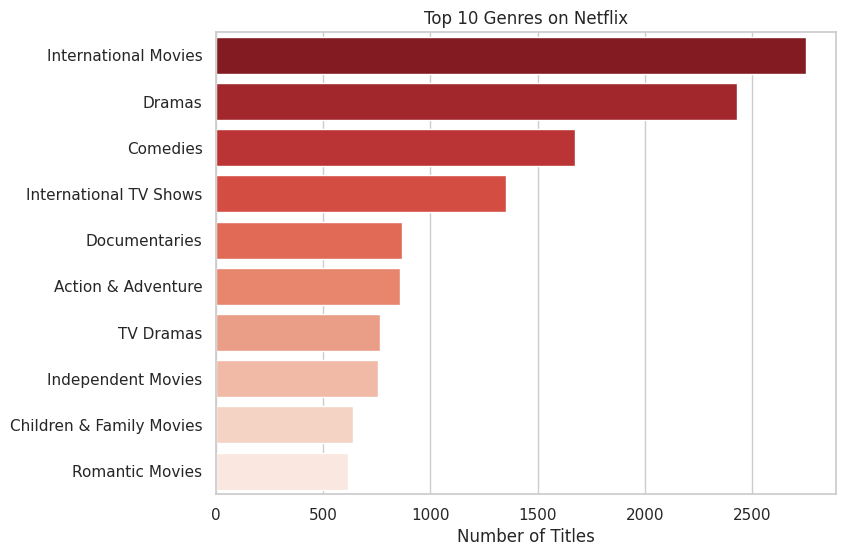

In [ ]:
plt.figure(figsize=(8,6))
genre_series = df['listed_in'].str.split(', ').explode()
top_genres = genre_series.value_counts().head(10)
sns.barplot(x=top_genres.values, y=top_genres.index, palette='Reds_r')
plt.title('Top 10 Genres on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('')
plt.show()

In [ ]:
# Save the cleaned/fixed dataset for Power BI import
df.to_csv('netflix_for_powerbi.csv', index=False)

from google.colab import files
files.download('netflix_for_powerbi.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>